# TP1 : Classification de voyelles par lois gaussiennes

### Vérification des données


In [5]:
import pickle
import matplotlib.pyplot as plt
import numpy as np

In [9]:
#1- Charger les données d'apprentissage avec le code suivant :
f = open('APP.pkl', 'rb')
dicoAPP = pickle.load(f)
app_aa = dicoAPP["aa"]
app_ii = dicoAPP["ii"]
app_uu = dicoAPP["uu"]
f.close()

# Vérifier le contenu et la taille des matrices
# Il s'agit de matrices 80x2 résultant d'une ACP sur une paramétrisation cepstrale (cf. cours M1 !).

Dimensions app_aa : (80, 2)
Dimensions app_ii : (80, 2)
Dimensions app_uu : (80, 2)


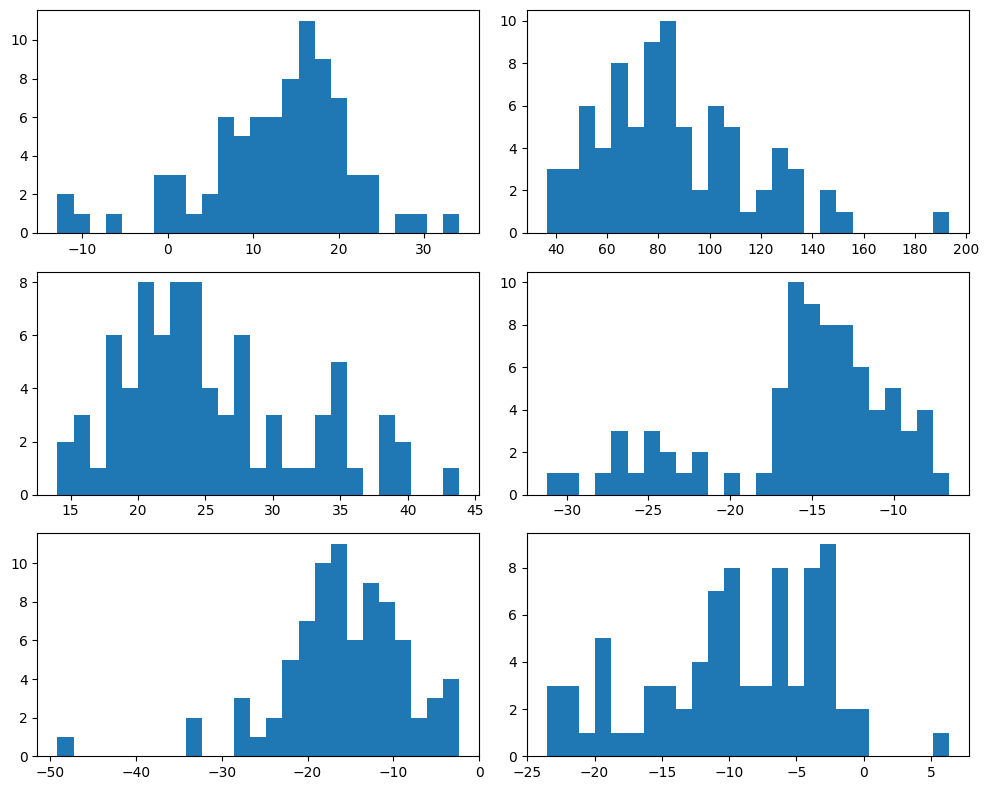

In [12]:
# 2- Afficher sur une seule figure, en utilisant subplot(nb_lignes, nb_colonnes, numero_trace),
# l'histogramme de chacune des classes : aa, uu et ii.

# Question 1 : Chargement et vérification des dimensions
with open('APP.pkl', 'rb') as f:
    dicoAPP = pickle.load(f)

app_aa = dicoAPP["aa"]
app_ii = dicoAPP["ii"]
app_uu = dicoAPP["uu"]

print("Dimensions app_aa :", app_aa.shape) # (80, 2)
print("Dimensions app_ii :", app_ii.shape) # (80, 2)
print("Dimensions app_uu :", app_uu.shape) # (80, 2)


# Question 2 : Affichage des histogrammes
# Question 2 : Affichage des histogrammes en grille (3 lignes, 2 colonnes)
plt.figure(figsize=(10, 8)) # Ajustez la taille de la figure si besoin

# --- CLASSE AA --- (Ligne 1)
# Composante 1 (gauche)
plt.subplot(3, 2, 1)
plt.hist(app_aa[:, 0], bins=25, color='C0') # 'C0' est le bleu par défaut
# Optionnel : plt.title("aa - Composante 1")

# Composante 2 (droite)
plt.subplot(3, 2, 2)
plt.hist(app_aa[:, 1], bins=25, color='C0')
# Optionnel : plt.title("aa - Composante 2")

# --- CLASSE UU --- (Ligne 2)
# Composante 1 (gauche)
plt.subplot(3, 2, 3)
plt.hist(app_uu[:, 0], bins=25, color='C0')
# Optionnel : plt.title("uu - Composante 1")

# Composante 2 (droite)
plt.subplot(3, 2, 4)
plt.hist(app_uu[:, 1], bins=25, color='C0')
# Optionnel : plt.title("uu - Composante 2")

# --- CLASSE II --- (Ligne 3)
# Composante 1 (gauche)
plt.subplot(3, 2, 5)
plt.hist(app_ii[:, 0], bins=25, color='C0')
# Optionnel : plt.title("ii - Composante 1")

# Composante 2 (droite)
plt.subplot(3, 2, 6)
plt.hist(app_ii[:, 1], bins=25, color='C0')
# Optionnel : plt.title("ii - Composante 2")

# Espacer et afficher proprement
plt.tight_layout()
plt.show()




# Que pouvez-vous conclure ? Ecrire quelques lignes pour exppiquer
# ...
# ...


### Utilisation de lois gaussiennes

In [14]:
#3- APPRENTISSAGE : estimer les paramètres (moyenne et matrice de covariance) de chaque classe
# Quelles sont les dimensions des variables crées ; que contiennent-elles ?

# Question 3 : Estimation des paramètres (moyenne et covariance)
m_aa = np.mean(app_aa, axis=0)
c_aa = np.cov(app_aa, rowvar=False)

m_uu = np.mean(app_uu, axis=0)
c_uu = np.cov(app_uu, rowvar=False)

m_ii = np.mean(app_ii, axis=0)
c_ii = np.cov(app_ii, rowvar=False)

print("Dimensions moyenne :", m_aa.shape)    # (2,) -> vecteur contenant les moyennes des 2 composantes
print("Dimensions covariance :", c_aa.shape) # (2, 2) -> matrice de variance-covariance 2D

Dimensions moyenne : (2,)
Dimensions covariance : (2, 2)


In [15]:
#4- RECONNAISSANCE : écrire une fonction "classer" qui renvoie la classe obtenue
# par maximum de vraisemblance sur les lois gaussiennes estimées (modèle de chaque classe)
# sur l'observation fournie en entrée :

# Question 4 : Fonction de classification par maximum de vraisemblance
def vraisemblance_gaussienne(x, m, c):
    d = len(m)
    diff = x - m
    det_c = np.linalg.det(c)
    inv_c = np.linalg.inv(c)
    norm = 1.0 / (np.power(2 * np.pi, d / 2.0) * np.sqrt(det_c))
    exponent = -0.5 * np.dot(np.dot(diff, inv_c), diff.T)
    return norm * np.exp(exponent)

def classer(x, m_aa, c_aa, m_uu, c_uu, m_ii, c_ii):
    p_aa = vraisemblance_gaussienne(x, m_aa, c_aa)
    p_uu = vraisemblance_gaussienne(x, m_uu, c_uu)
    p_ii = vraisemblance_gaussienne(x, m_ii, c_ii)

    # Renvoie 1 pour aa, 2 pour uu, 3 pour ii (selon l'ordre d'arguments)
    probas = [p_aa, p_uu, p_ii]
    return np.argmax(probas) + 1

# Exemple de résultat :
# classe = classer(tst_aa[0,:], m_aa, c_aa, m_uu, c_uu, m_ii, c_ii)
# => no_classe = 1

In [16]:
#5- Des observations à tester sont présentes dans le fichier Pickle suivant : TST.pkl
# Charger ces données de tests comme  pour les données d'apprentissage)
# Vérifier leur dimensions et leur contenu

# Question 5 : Chargement des données de test
with open('TST.pkl', 'rb') as f:
    dicoTST = pickle.load(f)

tst_aa = dicoTST["aa"]
tst_uu = dicoTST["uu"]
tst_ii = dicoTST["ii"]

print("Dimensions tst_aa :", tst_aa.shape) # Généralement (20, 2) d'après la Q8


Dimensions tst_aa : (20, 2)


In [17]:
#6- Définir la fonction tout_tester qui effectue tous les tests de classification

# Questions 6 & 7 : Test global, matrice de confusion et taux de reconnaissance
def tout_tester(tst_aa, tst_uu, tst_ii, m_aa, c_aa, m_uu, c_uu, m_ii, c_ii):
    matrice_confusion = np.zeros((3, 3), dtype=int)
    donnees_test = [tst_aa, tst_uu, tst_ii]

    for vraie_classe, dataset in enumerate(donnees_test):
        for obs in dataset:
            classe_predite = classer(obs, m_aa, c_aa, m_uu, c_uu, m_ii, c_ii)
            matrice_confusion[vraie_classe, classe_predite - 1] += 1

    taux_reco = np.trace(matrice_confusion) / np.sum(matrice_confusion)
    return matrice_confusion, taux_reco

mat_conf, taux = tout_tester(tst_aa, tst_uu, tst_ii, m_aa, c_aa, m_uu, c_uu, m_ii, c_ii)
print("Matrice de confusion :\n", mat_conf)
print("Taux de reconnaissance :", taux)


Matrice de confusion :
 [[20  0  0]
 [ 0 20  0]
 [ 0  0 20]]
Taux de reconnaissance : 1.0


In [18]:
#7- Réaliser les tests et afficher la matrice de confusion et le taux de bonne reconnaisance correspondant

mat_conf, taux = tout_tester(tst_aa, tst_uu, tst_ii, m_aa, c_aa, m_uu, c_uu, m_ii, c_ii)
print("Matrice de confusion :\n", mat_conf)
print("Taux de reconnaissance :", taux)

Matrice de confusion :
 [[20  0  0]
 [ 0 20  0]
 [ 0  0 20]]
Taux de reconnaissance : 1.0


### Visualisation  des résultats

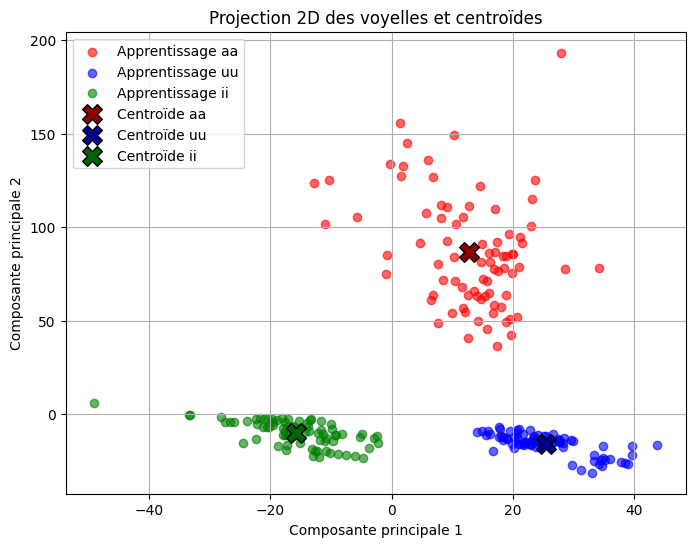

In [19]:
#9- Représenter en 2D et par des couleurs différentes les nuages de points correspondant
# aux données d'apprentissage

# Questions 9 & 10 : Nuages de points et centroïdes en 2D
plt.figure(figsize=(8, 6))

# Nuages de points d'apprentissage
plt.scatter(app_aa[:, 0], app_aa[:, 1], color='red', alpha=0.6, label='Apprentissage aa')
plt.scatter(app_uu[:, 0], app_uu[:, 1], color='blue', alpha=0.6, label='Apprentissage uu')
plt.scatter(app_ii[:, 0], app_ii[:, 1], color='green', alpha=0.6, label='Apprentissage ii')

# Centroïdes (moyennes)
plt.scatter(m_aa[0], m_aa[1], color='darkred', marker='X', s=200, edgecolor='black', label='Centroïde aa')
plt.scatter(m_uu[0], m_uu[1], color='darkblue', marker='X', s=200, edgecolor='black', label='Centroïde uu')
plt.scatter(m_ii[0], m_ii[1], color='darkgreen', marker='X', s=200, edgecolor='black', label='Centroïde ii')

plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")
plt.title("Projection 2D des voyelles et centroïdes")
plt.legend()
plt.grid(True)
plt.show()

#10- Afficher les centroïdes des différentes classes



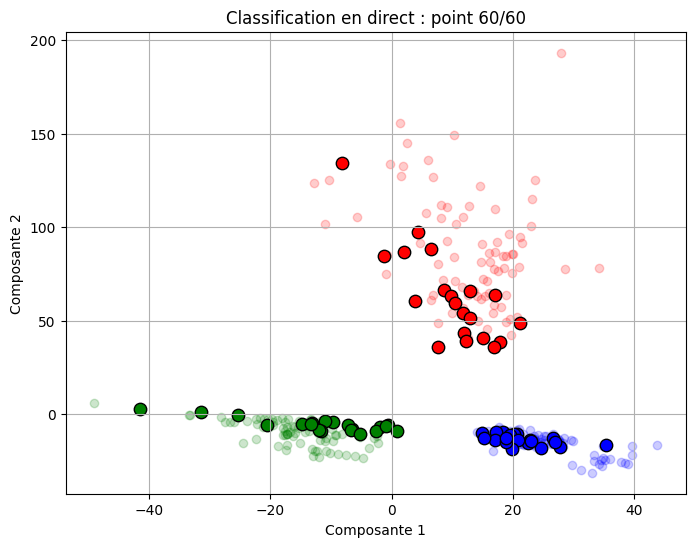

In [20]:
#11- Réaliser une animation pour l'affichage des points de test (un par un avec des couleurs par exemple...)


# Question 11 : Animation point par point des données de test (compatible Jupyter)
from IPython.display import clear_output
import time

couleurs = {1: 'red', 2: 'blue', 3: 'green'}
tous_tests = np.vstack((tst_aa, tst_uu, tst_ii))

for i, point in enumerate(tous_tests):
    clear_output(wait=True)
    plt.figure(figsize=(8, 6))

    # Fond : données d'apprentissage
    plt.scatter(app_aa[:, 0], app_aa[:, 1], color='red', alpha=0.2)
    plt.scatter(app_uu[:, 0], app_uu[:, 1], color='blue', alpha=0.2)
    plt.scatter(app_ii[:, 0], app_ii[:, 1], color='green', alpha=0.2)

    # Points déjà classés jusqu'à l'instant i
    for j in range(i + 1):
        p = tous_tests[j]
        pred = classer(p, m_aa, c_aa, m_uu, c_uu, m_ii, c_ii)
        plt.scatter(p[0], p[1], color=couleurs[pred], edgecolor='black', s=80)

    plt.title(f"Classification en direct : point {i+1}/{len(tous_tests)}")
    plt.xlabel("Composante 1")
    plt.ylabel("Composante 2")
    plt.grid(True)
    plt.show()
    time.sleep(0.15)
